# Air Quality Insight: EDA, Feature Engineering, and AQI Model

This notebook supports the DS Sprint Skill Based Assessment 2. It uses the supplied prepared air-quality CSV and the UCI source archive. The source contains one historical monitoring location, pollutant sensors, temperature, and relative humidity. It does **not** include station identifiers, traffic, wind, rainfall, or holiday data, so those assignment questions cannot be answered from the available files.

The AQI model estimates the provided same-period AQI label from same-period sensor readings. Treat it as a reconstruction/nowcast baseline, not a future forecast or causal analysis.

In [1]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

PROJECT_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'cleaned_air_quality.csv').exists())
DATA_PATH = PROJECT_ROOT / 'cleaned_air_quality.csv'


def summarize(frame):
    hourly = frame.groupby('hour')['AQI'].agg(['mean', 'median', 'count']).reset_index()
    seasonal = frame.groupby('season', observed=False)['AQI'].agg(['mean', 'median', 'count']).reset_index()
    weekday = frame.groupby('day_of_week_num')['AQI'].agg(['mean', 'median', 'count']).reset_index()
    weekday['day'] = weekday['day_of_week_num'].map(dict(enumerate(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'])))
    temperature_bins = pd.cut(frame['T'], bins=6, duplicates='drop')
    temperature = frame.groupby(temperature_bins, observed=False)['AQI'].agg(['mean', 'median', 'count']).reset_index()
    temperature['range'] = temperature['T'].astype(str)
    humidity_bins = pd.cut(frame['RH'], bins=6, duplicates='drop')
    humidity = frame.groupby(humidity_bins, observed=False)['AQI'].agg(['mean', 'median', 'count']).reset_index()
    humidity['range'] = humidity['RH'].astype(str)
    correlation = frame.select_dtypes('number').corr(numeric_only=True)['AQI'].drop('AQI')
    correlation = correlation.reindex(correlation.abs().sort_values(ascending=False).index)
    return {
        'hourly': hourly,
        'seasonal': seasonal,
        'weekday': weekday,
        'temperature': temperature[['range', 'mean', 'median', 'count']],
        'humidity': humidity[['range', 'mean', 'median', 'count']],
        'correlations': correlation.rename_axis('feature').reset_index(name='correlation_with_aqi'),
    }


def train_model(frame):
    target = 'AQI'
    excluded = {target, 'AQI_Category', 'timestamp', 'day_of_week'}
    features = [column for column in frame.columns if column not in excluded]
    numeric = [column for column in features if pd.api.types.is_numeric_dtype(frame[column])]
    categorical = [column for column in features if column not in numeric]
    split_at = int(len(frame) * 0.8)
    train, test = frame.iloc[:split_at], frame.iloc[split_at:]
    x_train, y_train = train[features], train[target]
    x_test, y_test = test[features], test[target]
    preprocessor = ColumnTransformer([
        ('numeric', SimpleImputer(strategy='median'), numeric),
        ('categorical', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore')),
        ]), categorical),
    ])
    model = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', RandomForestRegressor(
            n_estimators=220, min_samples_leaf=2, max_features=0.9,
            random_state=42, n_jobs=-1,
        )),
    ])
    model.fit(x_train, y_train)
    prediction = model.predict(x_test)
    baseline = DummyRegressor(strategy='mean').fit(x_train[numeric], y_train)
    baseline_prediction = baseline.predict(x_test[numeric])
    metrics = {
        'train_rows': len(train),
        'test_rows': len(test),
        'mae': mean_absolute_error(y_test, prediction),
        'rmse': math.sqrt(mean_squared_error(y_test, prediction)),
        'r2': r2_score(y_test, prediction),
        'baseline_mae': mean_absolute_error(y_test, baseline_prediction),
        'baseline_rmse': math.sqrt(mean_squared_error(y_test, baseline_prediction)),
    }
    importance = permutation_importance(
        model, x_test, y_test, n_repeats=2, random_state=42,
        scoring='neg_mean_absolute_error', n_jobs=-1,
    )
    importance_frame = pd.DataFrame({
        'feature': features,
        'importance': importance.importances_mean,
    }).sort_values('importance', ascending=False)
    return model, metrics, importance_frame

print('Submission folder:', PROJECT_ROOT)

Submission folder: c:\Users\HP\OneDrive\Desktop\DATA SCIENCE\ds_airquality_submission


## Load and Validate
Load the self-contained cleaned dataset included at the repository root, confirm its timestamp coverage, and review missing sensor data and duplicates.

In [2]:
air = pd.read_csv(DATA_PATH, parse_dates=['timestamp'])
air['season'] = pd.Categorical(air['season'], categories=['Winter', 'Spring', 'Summer', 'Autumn'], ordered=True)
data_quality = {
    'rows': len(air),
    'columns': len(air.columns),
    'missing_cells': int(air.isna().sum().sum()),
    'duplicate_timestamps': int(air['timestamp'].duplicated().sum()),
    'timestamp_start': air['timestamp'].min().isoformat(),
    'timestamp_end': air['timestamp'].max().isoformat(),
}
print('Rows / columns:', air.shape)
print('Time coverage:', air['timestamp'].min(), 'to', air['timestamp'].max())
display(pd.Series(data_quality, name='value').to_frame())
display(air.head())

Rows / columns: (8991, 25)
Time coverage: 2004-03-10 18:00:00 to 2005-04-04 14:00:00


,value
rows,8991
columns,25
missing_cells,12944
duplicate_timestamps,0
timestamp_start,2004-03-10T18:00:00
timestamp_end,2005-04-04T14:00:00


,timestamp,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),...,AQI_Category,hour,day_of_week,day_of_week_num,month,is_weekend,hour_sin,hour_cos,season,temp_humidity_interaction
0,2004-03-10 18:00:00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,...,Unhealthy for Sensitive Groups,18,Wednesday,2,3,0,-1.000000,-1.836970e-16,Spring,665.04
1,2004-03-10 19:00:00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,...,Unhealthy for Sensitive Groups,19,Wednesday,2,3,0,-0.965926,2.588190e-01,Spring,634.41
2,2004-03-10 20:00:00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,...,Unhealthy for Sensitive Groups,20,Wednesday,2,3,0,-0.866025,5.000000e-01,Spring,642.60
3,2004-03-10 21:00:00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,...,Unhealthy for Sensitive Groups,21,Wednesday,2,3,0,-0.707107,7.071068e-01,Spring,660.00
4,2004-03-10 22:00:00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,...,Unhealthy for Sensitive Groups,22,Wednesday,2,3,0,-0.500000,8.660254e-01,Spring,667.52


In [3]:
# The submitted cleaned file retains missing sensor readings as NaN and decodes -200 sentinels.
prepared = air.drop(columns=['timestamp', 'AQI_Category', 'day_of_week', 'season'], errors='ignore')
quality = pd.DataFrame({
    'missing_cells': prepared.isna().sum(),
    'sentinel_-200': prepared.select_dtypes('number').eq(-200).sum(),
}).fillna(0).astype(int)
display(quality.loc[quality.sum(axis=1).gt(0)])
print('Duplicate timestamps:', air['timestamp'].duplicated().sum())
display(air.select_dtypes('number').describe().T.round(2))

,missing_cells,sentinel_-200
CO(GT),1647,0
NMHC(GT),8104,0
NOx(GT),1595,0
NO2(GT),1598,0


Duplicate timestamps: 0


,count,mean,std,min,25%,50%,75%,max
CO(GT),7344.0,2.13,1.44,0.10,1.10,1.80,2.80,11.90
PT08.S1(CO),8991.0,1099.83,217.08,647.00,937.00,1063.00,1231.00,2040.00
NMHC(GT),887.0,218.61,206.62,7.00,66.00,145.00,297.00,1189.00
C6H6(GT),8991.0,10.08,7.45,0.10,4.40,8.20,14.00,63.70
PT08.S2(NMHC),8991.0,939.15,266.83,383.00,734.50,909.00,1116.00,2214.00
NOx(GT),7396.0,242.19,206.31,2.00,97.00,178.00,321.00,1479.00
PT08.S3(NOx),8991.0,835.49,256.82,322.00,658.00,806.00,969.50,2683.00
NO2(GT),7393.0,112.15,47.63,2.00,77.00,109.00,140.00,333.00
PT08.S4(NO2),8991.0,1456.26,346.21,551.00,1227.00,1463.00,1674.00,2775.00
PT08.S5(O3),8991.0,1022.91,398.48,221.00,731.50,963.00,1273.50,2523.00


In [4]:
# Missing readings remain NaN in the submitted cleaned file; sentinel codes have been decoded.
sensor_columns = [column for column in air.select_dtypes('number').columns if column not in ['AQI', 'hour', 'day_of_week_num', 'month', 'is_weekend', 'hour_sin', 'hour_cos', 'temp_humidity_interaction']]
source_missing = air[sensor_columns].isna().sum().sort_values(ascending=False)
display(source_missing[source_missing.gt(0)].to_frame('missing source readings'))

# IQR flags are for review only; valid pollution peaks are not dropped automatically.
measure_columns = [column for column in ['CO(GT)', 'NMHC(GT)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)', 'AQI'] if column in air.columns]
numeric = air[measure_columns]
q1 = numeric.quantile(0.25)
q3 = numeric.quantile(0.75)
iqr = q3 - q1
outlier_counts = ((numeric < q1 - 1.5 * iqr) | (numeric > q3 + 1.5 * iqr)).sum()
display(outlier_counts.sort_values(ascending=False).to_frame('IQR outlier rows'))

,missing source readings
NMHC(GT),8104
CO(GT),1647
NO2(GT),1598
NOx(GT),1595


,IQR outlier rows
AQI,416
NOx(GT),411
CO(GT),257
C6H6(GT),228
NO2(GT),98
NMHC(GT),55


## EDA and Feature Engineering
Explore time-of-day, weekday, seasonal, temperature, humidity, and pollutant relationships. Seasonal categories are calendar-derived; correlations describe association only.

In [5]:
tables = summarize(air)
display(tables['hourly'].round(2))
display(tables['seasonal'].round(2))
display(tables['weekday'].round(2))
display(tables['temperature'].round(2))
display(tables['humidity'].round(2))
display(tables['correlations'].head(12).round(3))

,hour,mean,median,count
0,0,123.92,123.00,372
1,1,112.73,112.50,374
2,2,99.27,101.25,375
3,3,129.89,132.15,376
4,4,94.91,101.62,377
5,5,83.45,81.25,377
6,6,94.92,92.50,376
7,7,117.33,121.00,376
8,8,139.95,132.15,376
9,9,147.37,137.00,378


,season,mean,median,count
0,Winter,155.37,147.00,1943
1,Spring,130.24,132.15,2763
2,Summer,115.05,121.00,2120
3,Autumn,130.99,132.15,2165


,day_of_week_num,mean,median,count,day
0,0,130.66,132.15,1303,Monday
1,1,135.76,132.15,1276,Tuesday
2,2,138.47,132.15,1251,Wednesday
3,3,138.84,132.15,1274,Thursday
4,4,140.15,132.15,1242,Friday
5,5,128.51,132.15,1328,Saturday
6,6,114.61,120.00,1317,Sunday


,range,mean,median,count
0,"(-1.946, 5.85]",151.04,140.00,701
1,"(5.85, 13.6]",144.81,134.00,2261
2,"(13.6, 21.35]",125.68,132.15,2819
3,"(21.35, 29.1]",122.03,132.15,2151
4,"(29.1, 36.85]",131.50,132.15,806
5,"(36.85, 44.6]",131.14,132.50,253


,range,mean,median,count
0,"(9.12, 22.45]",139.29,134.50,622
1,"(22.45, 35.7]",137.44,132.15,1615
2,"(35.7, 48.95]",132.79,132.15,2144
3,"(48.95, 62.2]",129.31,132.15,2331
4,"(62.2, 75.45]",127.32,132.15,1630
5,"(75.45, 88.7]",134.04,132.15,649


,feature,correlation_with_aqi
0,NO2(GT),0.988
1,NOx(GT),0.758
2,NMHC(GT),0.705
3,CO(GT),0.672
4,PT08.S5(O3),0.659
5,PT08.S3(NOx),-0.593
6,PT08.S1(CO),0.590
7,PT08.S2(NMHC),0.589
8,C6H6(GT),0.564
9,hour_sin,-0.336


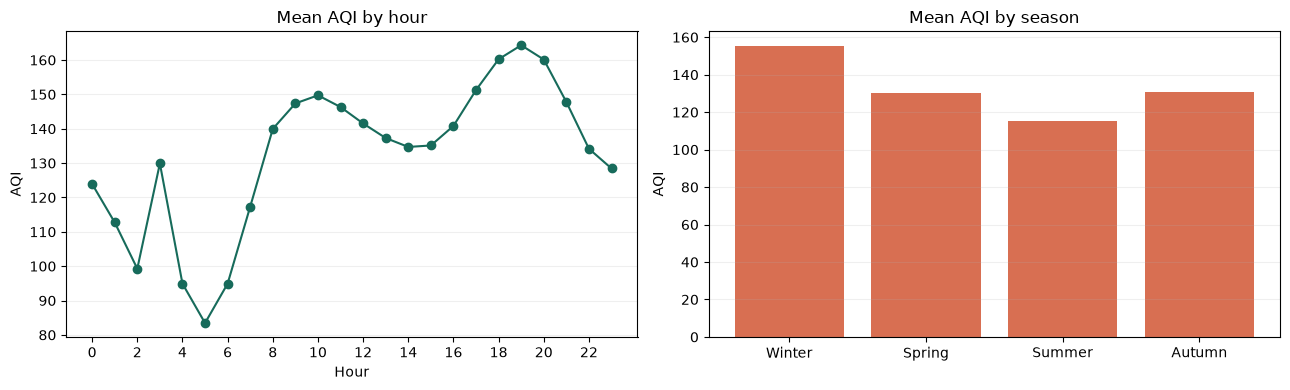

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(tables['hourly']['hour'], tables['hourly']['mean'], marker='o', color='#176B5B')
axes[0].set(title='Mean AQI by hour', xlabel='Hour', ylabel='AQI', xticks=range(0, 24, 2))
seasonal = tables['seasonal'].dropna(subset=['mean'])
axes[1].bar(seasonal['season'].astype(str), seasonal['mean'], color='#D86F52')
axes[1].set(title='Mean AQI by season', ylabel='AQI')
for axis in axes: axis.grid(axis='y', alpha=.2)
plt.tight_layout()

In [9]:
engineered = ['hour', 'day_of_week_num', 'month', 'is_weekend', 'hour_sin', 'hour_cos', 'season', 'temp_humidity_interaction']
display(air[engineered + ['AQI']].head(10))
print('AQI category distribution:')
display(air['AQI_Category'].value_counts().to_frame('records'))

,hour,day_of_week_num,month,is_weekend,hour_sin,hour_cos,season,temp_humidity_interaction,AQI
0,18,2,3,0,-1.000000,-1.836970e-16,Spring,665.04,133.000000
1,19,2,3,0,-0.965926,2.588190e-01,Spring,634.41,112.000000
2,20,2,3,0,-0.866025,5.000000e-01,Spring,642.60,134.000000
3,21,2,3,0,-0.707107,7.071068e-01,Spring,660.00,142.000000
4,22,2,3,0,-0.500000,8.660254e-01,Spring,667.52,136.000000
5,23,2,3,0,-0.258819,9.659258e-01,Spring,663.04,116.000000
6,0,3,3,0,0.000000,1.000000e+00,Spring,641.84,96.250000
7,1,3,3,0,0.258819,9.659258e-01,Spring,642.00,95.000000
8,2,3,3,0,0.500000,8.660254e-01,Spring,638.79,75.000000
9,3,3,3,0,0.707107,7.071068e-01,Spring,620.06,132.145137


AQI category distribution:


,records
AQI_Category,
Unhealthy for Sensitive Groups,4958
Unhealthy,1659
Moderate,1482
Very Unhealthy,635
Good,241
Hazardous,16


## Train and Evaluate
The final 20% of chronologically ordered observations is held out. A mean-prediction baseline provides a basic comparison. Permutation importance is measured on the holdout set.

,value
train_rows,7192.000000
test_rows,1799.000000
mae,0.484385
rmse,2.854663
r2,0.996909
baseline_mae,49.150980
baseline_rmse,62.879054


,feature,importance
7,NO2(GT),5.508833e+01
0,CO(GT),2.105456e+00
5,NOx(GT),7.965291e-01
4,PT08.S2(NMHC),3.339049e-02
6,PT08.S3(NOx),2.740904e-02
3,C6H6(GT),2.055055e-02
1,PT08.S1(CO),1.531708e-02
9,PT08.S5(O3),1.295841e-02
13,hour,3.224122e-03
18,hour_cos,2.381274e-03


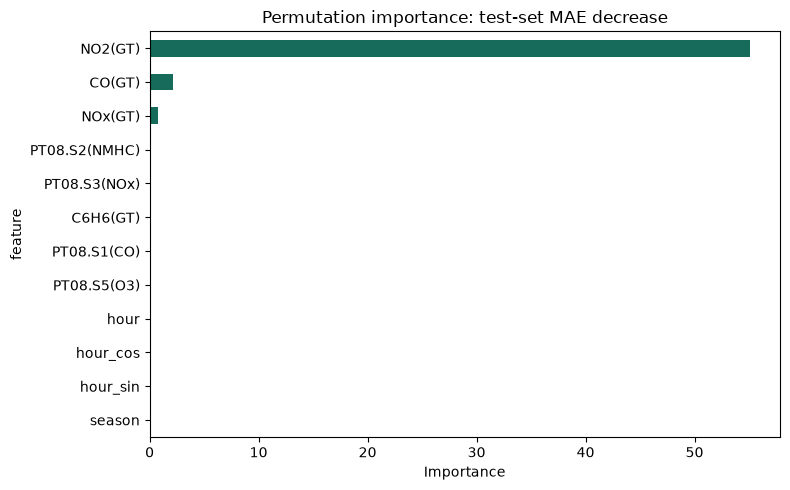

In [6]:
model, metrics, importance = train_model(air)
display(pd.Series(metrics, name='value').to_frame())
display(importance.head(15))
importance.head(12).sort_values('importance').plot.barh(x='feature', y='importance', legend=False, color='#176B5B', figsize=(8, 5))
plt.title('Permutation importance: test-set MAE decrease')
plt.xlabel('Importance')
plt.tight_layout()

## Submission Files
The cleaned dataset, this notebook, the Excel analysis workbook, and the business pitch are included at the repository root. The model is trained and evaluated in this notebook; no separate model file or project scripts are required to reproduce the analysis.

In [7]:
required_files = [
    'cleaned_air_quality.csv',
    'air_quality_eda.ipynb',
    'air_quality_analysis.xlsx',
    'ecoair_business_pitch.pptx',
]
missing_files = [name for name in required_files if not (PROJECT_ROOT / name).exists()]
if missing_files:
    raise FileNotFoundError(f'Missing submission files: {missing_files}')
print('All four PDF deliverables are present:')
for name in required_files:
    print('-', name)

All four PDF deliverables are present:
- cleaned_air_quality.csv
- air_quality_eda.ipynb
- air_quality_analysis.xlsx
- ecoair_business_pitch.pptx
